In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os
import pandas as pd
import numpy as np

# Let's inspect potential paths where the CSV might be located based on your root folders
possible_paths = [
    '/content/drive/MyDrive/Fraud-ATO-Detection/creditcard.csv',
    '/content/drive/MyDrive/Fraud-ATO-Detection./creditcard.csv',
    '/content/drive/MyDrive/Fraud-ATO-Detection/data/creditcard.csv',
    '/content/drive/MyDrive/Fraud-ATO-Detection./data/creditcard.csv'
]

loaded_successfully = False

for path in possible_paths:
    # If we find the file, load it and break
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"Success! Loaded dataset from: {path}")
        print("Dataset shape:", df.shape)
        loaded_successfully = True
        break

if not loaded_successfully:
    print("Could not find 'creditcard.csv' in the standard locations.")
    # Let's list what is inside the two folders to see if the file is named differently
    for folder in ['/content/drive/MyDrive/Fraud-ATO-Detection', '/content/drive/MyDrive/Fraud-ATO-Detection.']:
        if os.path.exists(folder):
            print(f"\nContents of '{folder}':")
            try:
                print(os.listdir(folder))
            except Exception as e:
                print(f"Error reading folder: {e}")

Success! Loaded dataset from: /content/drive/MyDrive/Fraud-ATO-Detection./data/creditcard.csv
Dataset shape: (284807, 31)


In [8]:
X = df.drop('Class', axis=1)
y = df['Class']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (284807, 30)
Target: (284807,)


In [9]:
# Sort transactions chronologically
df = df.sort_values('Time').reset_index(drop=True)

# Separate features and target
X = df.drop('Class', axis=1)
y = df['Class']

# Use the first 80% for training
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())

Training data: (227845, 30)
Testing data: (56962, 30)
Training fraud cases: 417
Testing fraud cases: 75


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Features that need scaling
scale_features = ['Time', 'Amount']

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), scale_features)
    ],
    remainder='passthrough'
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [11]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [12]:
y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [13]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print(classification_report(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56887
           1       0.07      0.89      0.13        75

    accuracy                           0.98     56962
   macro avg       0.54      0.94      0.56     56962
weighted avg       1.00      0.98      0.99     56962

Precision: 0.07074973600844774
Recall: 0.8933333333333333
F1 Score: 0.13111545988258316


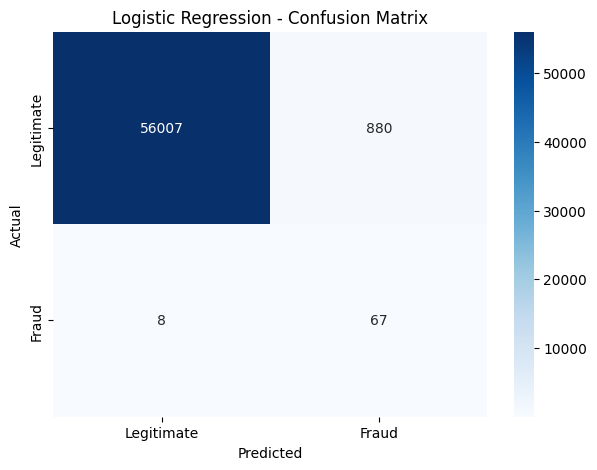

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()

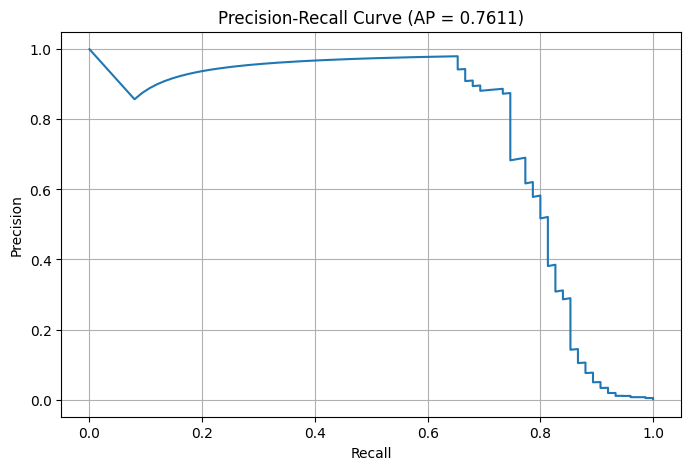

Average Precision: 0.7610555147933941


In [15]:
from sklearn.metrics import precision_recall_curve, average_precision_score

y_scores = model.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_scores
)

ap = average_precision_score(y_test, y_scores)

plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AP = {ap:.4f})')

plt.grid()
plt.show()

print("Average Precision:", ap)